In [1]:
import os.path as op

import matplotlib.pyplot as plt

import hnn_core
from hnn_core.params import _short_name

from hnn_core import new_calcium_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'

# The number of cores may need modifying depending on your current machine.
n_procs = 10

In [2]:
from urllib.request import urlretrieve

data_url = ('https://raw.githubusercontent.com/jonescompneurolab/hnn/master/data/MEG_detection_data/yes_trial_S1_ERP_all_avg.txt')
urlretrieve(data_url, 'yes_trial_S1_ERP_all_avg.txt')
exp_dpl = read_dipole('yes_trial_S1_ERP_all_avg.txt')

## Handtune

In [3]:
# Proximal 1
weights_ampa_p1 = {'L2_basket': 0.08831, 'L2_pyramidal': 0.1525*0.25,
                   'L5_basket': 0.19934, 'L5_pyramidal': 0.0865}
weights_nmda_p1 = None#{'L2_basket': 0.9240*0.1, 'L2_pyramidal': 0.0845*0.1,
                    #'L5_basket': 0.5849*0.1, 'L5_pyramidal': 0.65105*0.1}

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}

# Distal
weights_ampa_d1 = {'L2_basket': 0.8037*0.5, 'L2_pyramidal': 0.5738*0.1,
                   'L5_pyramidal': 0.3626*0.1}
weights_nmda_d1 = {'L2_basket': 0.2492*0.5, 'L2_pyramidal': 0.6183*0.1,
                   'L5_pyramidal': 0.1121*0.1}
synaptic_delays_d1 = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                      'L5_pyramidal': 0.1}


# Proximal 2
weights_ampa_p2 = {'L2_basket': 0.001, 'L2_pyramidal': 0.9, 'L5_basket': 0.001,
                   'L5_pyramidal': 0.9}
weights_nmda_p2 = {'L2_basket': 0.0001, 'L2_pyramidal': 1., 'L5_basket': 0.0001,
                   'L5_pyramidal': .8}

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

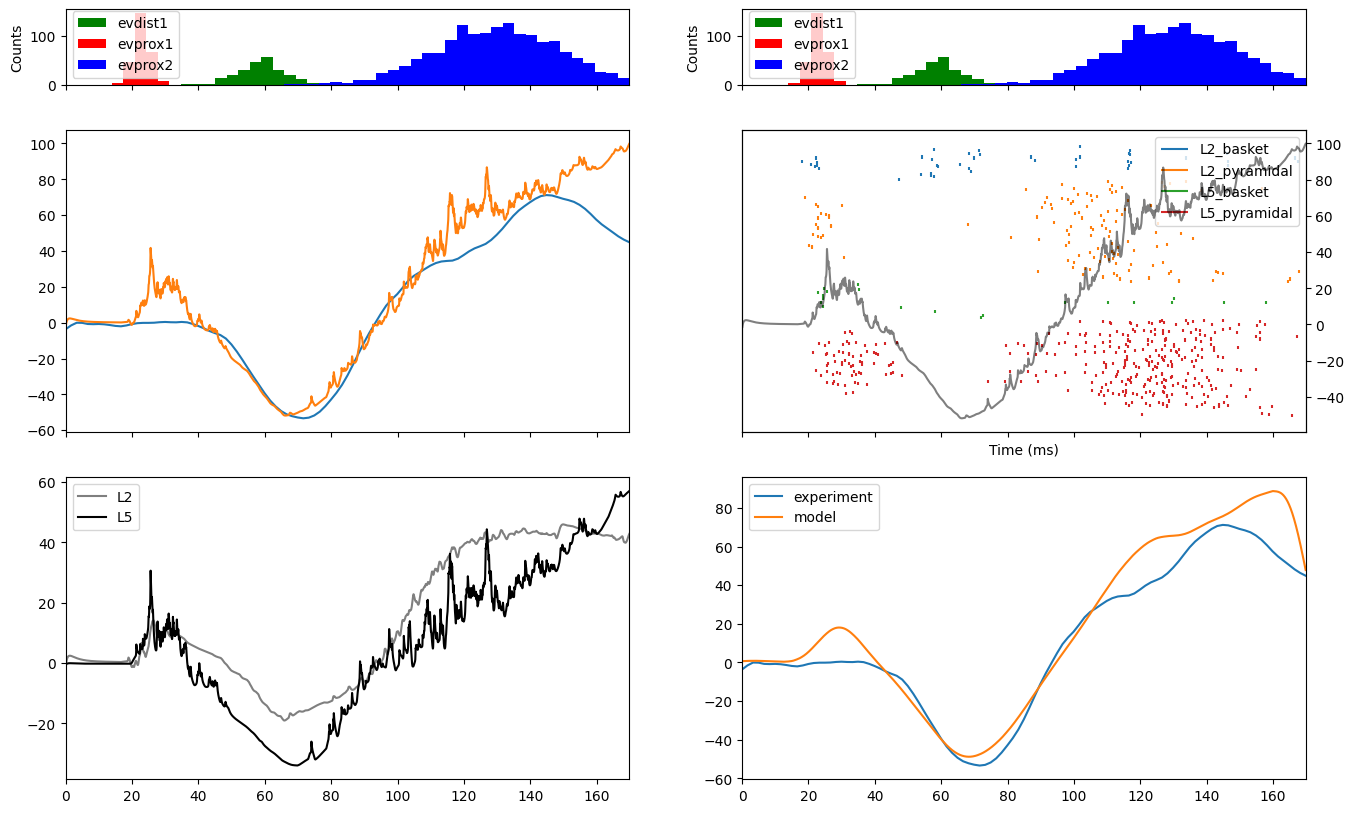

In [4]:
tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 20

net_init = new_calcium_model()

net_init.add_evoked_drive('evprox1',
                          mu=23, sigma=2.47,
                          numspikes=1,
                          location='proximal',
                          weights_ampa=weights_ampa_p1,
                          weights_nmda=weights_nmda_p1,
                          synaptic_delays=synaptic_delays_p, event_seed=544)


net_init.add_evoked_drive('evdist1',
                          mu=58.6539,
                          sigma=7,
                          numspikes=1,
                          location='distal',
                          weights_ampa=weights_ampa_d1,
                          weights_nmda=weights_nmda_d1,
                          synaptic_delays=synaptic_delays_d1)


net_init.add_evoked_drive('evprox2',
                          mu=130,
                          sigma=19,
                          numspikes=6,
                          location='proximal',
                          weights_ampa=weights_ampa_p2,
                          weights_nmda=weights_nmda_p2,
                          synaptic_delays=synaptic_delays_p)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    init_dpl = simulate_dipole(net_init, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]

init_dpl.scale(scale_factor)#.smooth(smooth_window_len)


fig, ax = plt.subplots(3,2,figsize=(16,10), height_ratios=[0.25,1,1], sharex=True)

net_init.cell_response.plot_spikes_hist(ax=ax[0,0], spike_types=['evprox1', 'evdist1', 'evprox2'], show=False)
net_init.cell_response.plot_spikes_hist(ax=ax[0,1], spike_types=['evprox1', 'evdist1', 'evprox2'], show=False)


ax[1,0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment')

ax[1,0].plot(init_dpl.times,init_dpl.data['agg'], label='model')

net_init.cell_response.plot_spikes_raster(ax=ax[1,1], show=False)
ax2 = ax[1,1].twinx()
ax2.plot(init_dpl.times,init_dpl.data['agg'],color='k', alpha=0.5)

ax[2,0].plot(init_dpl.times,init_dpl.data['L2'], label='L2', color='k', alpha=0.5)
ax[2,0].plot(init_dpl.times,init_dpl.data['L5'], label='L5', color='k')
ax[2,0].legend()

ax[2,1].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment')

smooth_dpl = init_dpl.smooth(smooth_window_len)
ax[2,1].plot(smooth_dpl.times,smooth_dpl.data['agg'], label='model')
ax[2,1].legend()


# fig.savefig(os.path.join(pathfig,'initial_dpl.png'))

## Proximal 2

In [5]:
def set_params(net, params):

    # Proximal 1
    weights_ampa_p1 = {'L2_basket': 0.08831, 'L2_pyramidal': 0.1525*0.25,
                    'L5_basket': 0.19934, 'L5_pyramidal': 0.0865}
    weights_nmda_p1 = None#{'L2_basket': 0.9240*0.1, 'L2_pyramidal': 0.0845*0.1,
                        #'L5_basket': 0.5849*0.1, 'L5_pyramidal': 0.65105*0.1}

    synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}

    # Distal
    weights_ampa_d1 = {'L2_basket': 0.8037*0.5, 'L2_pyramidal': 0.5738*0.1,
                    'L5_pyramidal': 0.3626*0.1}
    weights_nmda_d1 = {'L2_basket': 0.2492*0.5, 'L2_pyramidal': 0.6183*0.1,
                    'L5_pyramidal': 0.1121*0.1}
    synaptic_delays_d1 = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_pyramidal': 0.1}
        
    net.add_evoked_drive('evprox1',
                          mu=23,
                          sigma=2.47,
                          numspikes=1,
                          location='proximal',
                          weights_ampa=weights_ampa_p1,
                          weights_nmda=weights_nmda_p1,
                          synaptic_delays=synaptic_delays_p, event_seed=544)


    net.add_evoked_drive('evdist1',
                            mu=58.6539,
                            sigma=7,
                            numspikes=1,
                            location='distal',
                            weights_ampa=weights_ampa_d1,
                            weights_nmda=weights_nmda_d1,
                            synaptic_delays=synaptic_delays_d1, event_seed=544)


    weights_ampa_p2 = {'L2_basket':
                       params['evprox2_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evprox2_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['evprox2_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['evprox2_ampa_L5_pyramidal']}
    weights_nmda_p2 = {'L2_basket':
                       params['evprox2_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evprox2_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['evprox2_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['evprox2_nmda_L5_pyramidal']}
    
    net.add_evoked_drive('evprox2',
                         mu=params['evprox2_mu'],
                         sigma=params['evprox2_sigma'],
                         numspikes=int(params['evprox2_num_spikes']),
                         location='proximal',
                         weights_ampa=weights_ampa_p2,
                         weights_nmda=weights_nmda_p2,
                         synaptic_delays=synaptic_delays_p, event_seed=544)
    
    delay = net.delay

constraints = dict({
                'evprox2_ampa_L2_basket': (0.01, 1.),
                'evprox2_ampa_L2_pyramidal': (0.01, 1.),
                'evprox2_ampa_L5_basket': (0.01, 1.),
                'evprox2_ampa_L5_pyramidal': (0.01, 1.),
                'evprox2_nmda_L2_basket': (0.01, 1.),
                'evprox2_nmda_L2_pyramidal': (0.01, 1.),
                'evprox2_nmda_L5_basket': (0.01, 1.),
                'evprox2_nmda_L5_pyramidal': (0.01, 1.),
                'evprox2_mu': (110., 150.),
                'evprox2_sigma': (1., 25.),
                'evprox2_num_spikes': (1, 10)
                })
    


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

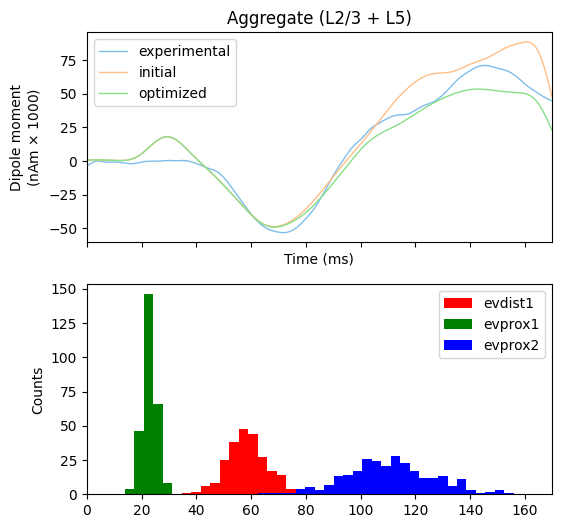

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/optimization/general_optimization.py:182: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show(show)


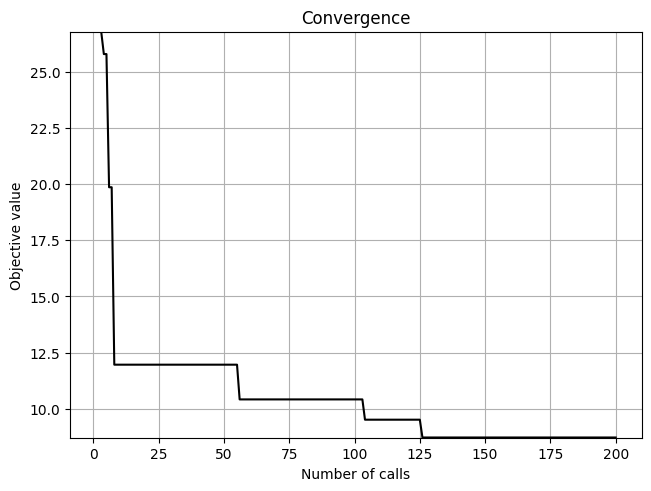

In [6]:

net = new_calcium_model()
optim = Optimizer(net, tstop=tstop, constraints=constraints,
                  set_params=set_params, solver='bayesian', obj_fun='dipole_rmse', max_iter=200)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    optim.fit(target=exp_dpl, scale_factor=scale_factor,
              smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_dpl = simulate_dipole(optim.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
opt_dpl.scale(scale_factor)
opt_dpl.smooth(smooth_window_len)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim.plot_convergence()

## Proximal 1

In [7]:
p2_optim_drives = optim.net_.external_drives['evprox2'].copy()


In [43]:
# optimize distal drive
def set_params_prox1(net, params):

    # Distal
    synaptic_delays_d1 = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_pyramidal': 0.1}

    # Distal
    weights_ampa_d1 = {'L2_basket': 0.8037*0.5, 'L2_pyramidal': 0.5738*0.1,
                    'L5_pyramidal': 0.3626*0.1}
    weights_nmda_d1 = {'L2_basket': 0.2492*0.5, 'L2_pyramidal': 0.6183*0.1,
                    'L5_pyramidal': 0.1121*0.1}
    synaptic_delays_d1 = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_pyramidal': 0.1}
    

    net.add_evoked_drive('evdist1',
                            mu=58.6539,
                            sigma=7,
                            numspikes=1,
                            location='distal',
                            weights_ampa=weights_ampa_d1,
                            weights_nmda=weights_nmda_d1,
                            synaptic_delays=synaptic_delays_d1, event_seed=544)
    

    # Proximal 2
    synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}

    net.add_evoked_drive('evprox2',
                         mu=p2_optim_drives['dynamics']['mu'],
                         sigma=p2_optim_drives['dynamics']['sigma'],
                         numspikes=p2_optim_drives['dynamics']['numspikes'],
                         location='proximal',
                         weights_ampa=p2_optim_drives['weights_ampa'],
                         weights_nmda=p2_optim_drives['weights_nmda'],
                         synaptic_delays=synaptic_delays_p)
    

    # Proximal 1
    weights_ampa_p1 = {'L2_basket':
                       params['evprox1_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evprox1_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['evprox1_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['evprox1_ampa_L5_pyramidal']}
    weights_nmda_p2 = {'L2_basket':
                       params['evprox1_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evprox1_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['evprox1_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['evprox1_nmda_L5_pyramidal']}
    
    net.add_evoked_drive('evprox1',
                         mu=params['evprox1_mu'],
                         sigma=params['evprox1_sigma'],
                         numspikes=int(params['evprox1_num_spikes']),
                         location='proximal',
                         weights_ampa=weights_ampa_p1,
                         weights_nmda=weights_nmda_p1,
                         synaptic_delays=synaptic_delays_p, event_seed=544)
    
    
    delay = net.delay

constraints = dict({
                'evprox1_ampa_L2_basket': (0.01, 1.),
                'evprox1_ampa_L2_pyramidal': (0.01, 1.),
                'evprox1_ampa_L5_basket': (0.01, 1.),
                'evprox1_ampa_L5_pyramidal': (0.01, 1.),
                'evprox1_nmda_L2_basket': (0.01, 1.),
                'evprox1_nmda_L2_pyramidal': (0.01, 1.),
                'evprox1_nmda_L5_basket': (0.01, 1.),
                'evprox1_nmda_L5_pyramidal': (0.01, 1.),
                'evprox1_mu': (10, 30.),
                'evprox1_sigma': (1., 5.),
                'evprox1_num_spikes': (1, 3)
                })

In [44]:
net = new_calcium_model()

optim_prox1 = Optimizer(net, tstop=tstop, constraints=constraints,
                  set_params=set_params_prox1, solver='bayesian', obj_fun='dipole_rmse', max_iter=400)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    optim_prox1.fit(target=exp_dpl, scale_factor=scale_factor,
              smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_dpl = simulate_dipole(optim_prox1.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
opt_dpl.scale(scale_factor)
opt_dpl.smooth(smooth_window_len)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

KeyboardInterrupt: 

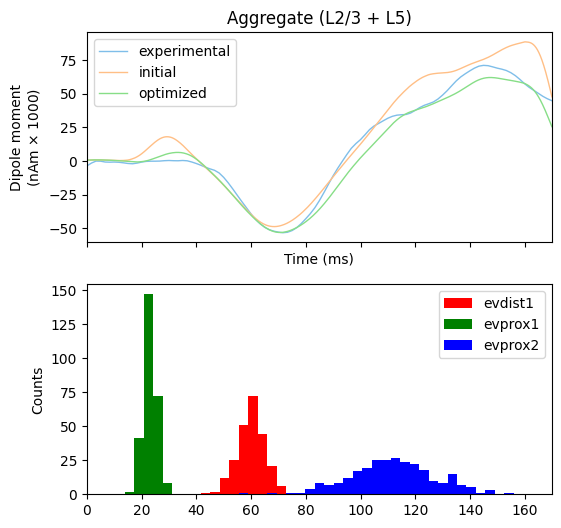

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/optimization/general_optimization.py:182: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show(show)


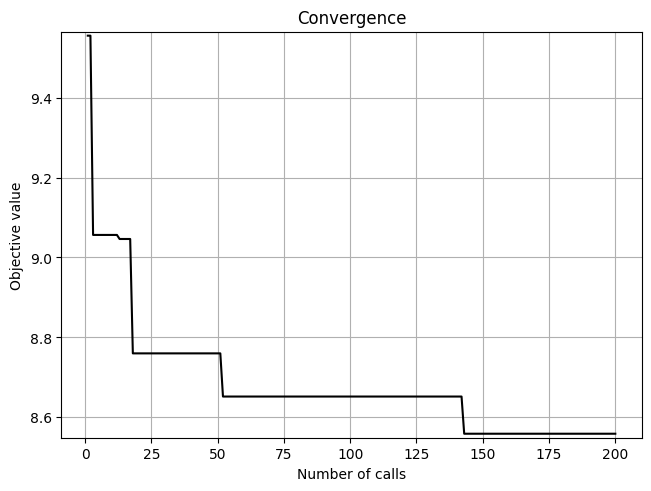

In [ ]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim_prox1.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim_prox1.plot_convergence()

## Distal 1

In [ ]:
p1_optim_drives = optim_prox1.net_.external_drives['evprox1'].copy()


In [ ]:
# optimize distal drive
def set_params_dist(net, params):

    # Distal

    weights_ampa_d1 = {'L2_basket':
                       params['evdist1_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evdist1_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['evdist1_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['evdist1_ampa_L5_pyramidal']}
    weights_nmda_d1 = {'L2_basket':
                       params['evdist1_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evdist1_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['evdist1_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['evdist1_nmda_L5_pyramidal']}
    synaptic_delays_d1 = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_pyramidal': 0.1}

    
    net.add_evoked_drive('evdist1',
                            mu=params['evdist1_mu'],
                            sigma=params['evdist1_sigma'],
                            numspikes=1,
                            location='distal',
                            weights_ampa=weights_ampa_d1,
                            weights_nmda=weights_nmda_d1,
                            synaptic_delays=synaptic_delays_d1)
    

    # Proximal 2
    synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}

    net.add_evoked_drive('evprox2',
                         mu=p2_optim_drives['dynamics']['mu'],
                         sigma=p2_optim_drives['dynamics']['sigma'],
                         numspikes=1,
                         location='proximal',
                         weights_ampa=p2_optim_drives['weights_ampa'],
                         weights_nmda=p2_optim_drives['weights_nmda'],
                         synaptic_delays=synaptic_delays_p)
    

    # Proximal 1
    
    net.add_evoked_drive('evprox1',
                        mu=p1_optim_drives['dynamics']['mu'],
                        sigma=p1_optim_drives['dynamics']['sigma'],
                        numspikes=1,
                        location='proximal',
                        weights_ampa=p1_optim_drives['weights_ampa'],
                        weights_nmda=p1_optim_drives['weights_nmda'],
                        synaptic_delays=synaptic_delays_p)
    
    
    delay = net.delay

constraints = dict({
                'evdist1_ampa_L2_basket': (0.01, 1.),
                'evdist1_ampa_L2_pyramidal': (0.01, 1.),
                'evdist1_ampa_L5_basket': (0.01, 1.),
                'evdist1_ampa_L5_pyramidal': (0.01, 1.),
                'evdist1_nmda_L2_basket': (0.01, 1.),
                'evdist1_nmda_L2_pyramidal': (0.01, 1.),
                'evdist1_nmda_L5_basket': (0.01, 1.),
                'evdist1_nmda_L5_pyramidal': (0.01, 1.),
                'evdist1_mu': (50, 80.),
                'evdist1_sigma': (5., 10.)
                })

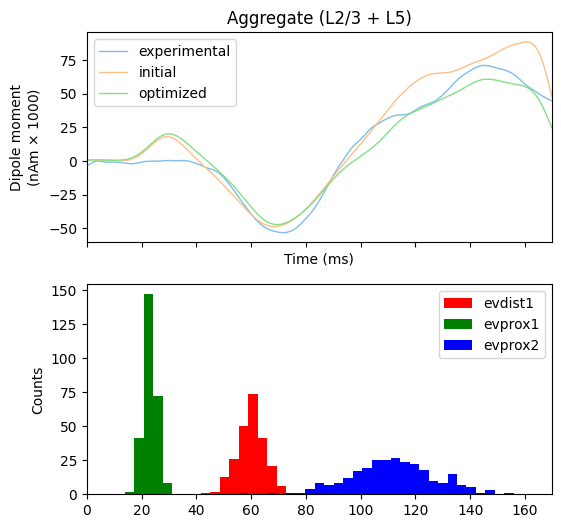

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/optimization/general_optimization.py:182: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show(show)


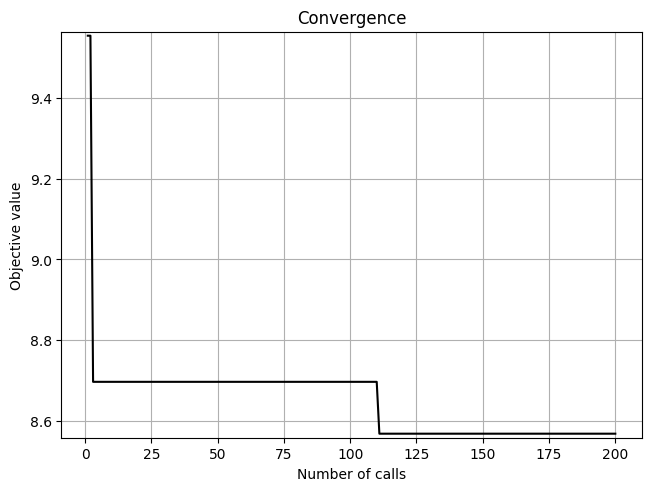

In [ ]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim.plot_convergence()

In [18]:
d1_optim_drives = optim.net_.external_drives['evdist1'].copy()


AttributeError: 'NoneType' object has no attribute 'external_drives'

In [16]:
net = new_calcium_model()

optim = Optimizer(net, tstop=tstop, constraints=constraints,
                  set_params=set_params_dist, solver='bayesian', obj_fun='dipole_rmse', max_iter=200)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    optim.fit(target=exp_dpl, scale_factor=scale_factor,
              smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_dpl = simulate_dipole(optim.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
opt_dpl.scale(scale_factor)
opt_dpl.smooth(smooth_window_len)


fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim.plot_convergence()

AttributeError: 'Network' object has no attribute 'add_voltage_drive'

In [12]:
# optim = Optimizer(tuned_net, tstop=tstop, constraints=constraints,
#                   set_params=set_params_dist, solver='bayesian', obj_fun='dipole_rmse', max_iter=500)

# with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
#     optim.fit(target=exp_dpl, scale_factor=scale_factor,
#               smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
# with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
#     opt_dpl = simulate_dipole(optim.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
# opt_dpl.scale(scale_factor)
# opt_dpl.smooth(smooth_window_len)

In [13]:
# fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# # plot original
# exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
# init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
# opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
# axes[0].legend(['experimental', 'initial', 'optimized'])
# optim.net_.cell_response.plot_spikes_hist(ax=axes[1])

# fig1 = optim.plot_convergence()

In [14]:
# import pickle

# with open('optim_net.pkl', 'wb') as file:
#         pickle.dump(optim.net_, file)